**DATA ANALYSIS PIPELINE** 

This notebook can be run based on the data available in the raw data folder. 

1. Reads all data files
2. Mergers into one dataset
3. Calculate duplicate entries and drops them (we can decide what to do, just drops them now to reduce size for analysis)
4. Missing values Analysis
5. Visualizations of selected features.
6. Data scoping analysis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import os
import warnings
warnings.filterwarnings('ignore')

# Set style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)

# Set paths
path = r"c:\Users\dilun\OneDrive\Diluni Peiris\Masters_AIM\Term 3\AID 504_ML Foundations and Applications\Final ML Project\philgeps-ml-project\data\raw"
print(f"Data path: {path}")

Data path: c:\Users\dilun\OneDrive\Diluni Peiris\Masters_AIM\Term 3\AID 504_ML Foundations and Applications\Final ML Project\philgeps-ml-project\data\raw


## TASK 1: READ ALL DATA FILES

In [2]:
# Find all CSV files
csv_files = sorted([f for f in os.listdir(path) if f.endswith('.csv')])
print(f"Found {len(csv_files)} CSV files:\n")
for i, f in enumerate(csv_files, 1):
    print(f"{i}. {f}")

# Read all CSV files
dataframes = {}
file_info = []

print("\n" + "="*80)
print("Loading files...\n")

for file in csv_files:
    filepath = os.path.join(path, file)
    try:
        df = pd.read_csv(filepath)
        dataframes[file] = df
        file_info.append({
            'File': file,
            'Rows': len(df),
            'Columns': len(df.columns),
            'Size (MB)': round(os.path.getsize(filepath) / (1024*1024), 2)
        })
        print(f"✓ {file}: {len(df):,} rows, {len(df.columns)} columns")
    except Exception as e:
        print(f"✗ {file}: Error - {e}")

print(f"\n✓ Successfully loaded {len(dataframes)} files")

Found 20 CSV files:

1. 1.5_2024_Q1.csv
2. 1.5_2025_Q1.csv
3. 1.5_2025_Q2.csv
4. 1.5_2025_Q3.csv
5. 1.5_2025_Q4.csv
6. 2.0_2023_Q1.csv
7. 2.0_2023_Q2.csv
8. 2.0_2023_Q3.csv
9. 2.0_2023_Q4.csv
10. 2.0_2024_Q1.csv
11. 2.0_2024_Q2.csv
12. 2.0_2024_Q3.csv
13. 2.0_2024_Q4.csv
14. 2.0_2025_Q1.csv
15. 2.0_2025_Q2.csv
16. 2.0_2025_Q3.csv
17. 2.0_2025_Q4.csv
18. 2.0_2026_Q1.csv
19. 2.0_2026_Q2.csv
20. 2.0_2026_Q3.csv

Loading files...

✓ 1.5_2024_Q1.csv: 440,342 rows, 46 columns
✓ 1.5_2025_Q1.csv: 469,569 rows, 46 columns
✓ 1.5_2025_Q2.csv: 372,122 rows, 46 columns
✓ 1.5_2025_Q3.csv: 361,502 rows, 46 columns
✗ 1.5_2025_Q4.csv: Error - 'utf-8' codec can't decode byte 0xf1 in position 25927: invalid continuation byte
✓ 2.0_2023_Q1.csv: 405,796 rows, 46 columns
✓ 2.0_2023_Q2.csv: 436,736 rows, 46 columns
✓ 2.0_2023_Q3.csv: 450,701 rows, 46 columns
✓ 2.0_2023_Q4.csv: 450,311 rows, 46 columns
✓ 2.0_2024_Q1.csv: 440,342 rows, 46 columns


KeyboardInterrupt: 

## TASK 2 & 3: MERGE DATA AND SOURCE SUMMARY

In [3]:
# Merge all dataframes
merged_df = pd.concat(dataframes.values(), ignore_index=True)
print(f"Merged DataFrame: {merged_df.shape[0]:,} rows × {merged_df.shape[1]} columns")
print(f"\nColumn Names:")
print(merged_df.columns.tolist())

# Summary of source files
summary_df = pd.DataFrame(file_info)
print("\n" + "="*80)
print("SOURCE FILES SUMMARY")
print("="*80)
print(summary_df.to_string(index=False))
print(f"\nTotal Size: {summary_df['Size (MB)'].sum():.2f} MB")
print(f"Total Rows: {summary_df['Rows'].sum():,}")
print(f"Average Columns: {summary_df['Columns'].mean():.0f}")

Merged DataFrame: 6,634,889 rows × 61 columns

Column Names:
['Procuring Entity (PE)', 'Region', 'Province', 'City/Municipality', 'Government Branch', 'PE Organization Type', 'PE Organization Type (Grouped)', 'Bid Reference No.', 'Notice Title', 'Classification', 'Procurement Mode', 'Business Category', 'Funding Source', 'Funding Instrument', 'Trade Agreement', 'Approved Budget of the Contract', 'Published Date', 'Closing Date', 'Area of Delivery', 'Contract Duration', 'Calendar Type', 'Line Item No', 'Item Name', 'Item Description', 'Quantity', 'UOM', 'Item Budget', 'Bid Notice Status', 'Award Reference No.', 'Award Title', 'UNSPSC Code', 'UNSPSC Description', 'Published Date(Award)', 'Award Date', 'Contract Amount', 'Award Notice Status', 'Notice to Proceed Date', 'Contract Effectivity Date', 'Contract End Date', 'Awardee Organization Name', 'Country of Awardee', 'Region of Awardee', 'Province of Awardee', 'City/Municipality of Awardee', 'Awardee Size', 'Awardee Joint Venture', 'Proc

## TASK 4.1: DUPLICATE ANALYSIS

Keeping the last entry and dropping the rest assuming it contains the last bid status.

In [11]:
print("="*80)
print("DUPLICATE ANALYSIS")
print("="*80)

before_drop = len(merged_df)
print(f"\nRows before removing duplicates: {before_drop:,}")

duplicates = merged_df.duplicated().sum()
print(f"Duplicate rows found: {duplicates:,}")

merged_df_clean = merged_df.drop_duplicates(keep='last')
after_drop = len(merged_df_clean)
print(f"Rows after removing duplicates: {after_drop:,}")
print(f"Rows removed: {before_drop - after_drop:,} ({((before_drop-after_drop)/before_drop*100):.2f}%)")

print(f"\n✓ Cleaned dataset: {merged_df_clean.shape[0]:,} rows × {merged_df_clean.shape[1]} columns")

DUPLICATE ANALYSIS

Rows before removing duplicates: 6,634,889
Duplicate rows found: 2,092,243
Rows after removing duplicates: 4,542,646
Rows removed: 2,092,243 (31.53%)

✓ Cleaned dataset: 4,542,646 rows × 61 columns


## TASK 4.2: MISSING VALUES AND DATA TYPES

In [12]:
print("="*80)
print("MISSING VALUES SUMMARY")
print("="*80)

missing = pd.DataFrame({
    'Column': merged_df_clean.columns,
    'Missing Count': merged_df_clean.isnull().sum().values,
    'Missing %': (merged_df_clean.isnull().sum().values / len(merged_df_clean) * 100).round(2)
})
missing_sorted = missing[missing['Missing Count'] > 0].sort_values('Missing %', ascending=False)

if len(missing_sorted) > 0:
    print("\nColumns with missing values:")
    print(missing_sorted.to_string(index=False))
else:
    print("\n✓ No missing values found!")

print("\n" + "="*80)
print("DATA TYPES SUMMARY")
print("="*80)

dtype_summary = pd.DataFrame({
    'Column': merged_df_clean.columns,
    'Data Type': merged_df_clean.dtypes.values
})
print("\n" + dtype_summary.to_string(index=False))

MISSING VALUES SUMMARY

Columns with missing values:
                                Column  Missing Count  Missing %
          Awardee Size (MSME Category)        4520107      99.50
            Award Notice Status (Item)        4519429      99.49
                       Item/Lot Name.1        4519429      99.49
                Published Date (Award)        4519429      99.49
     Area of Delivery/Project Location        4411779      97.12
                       Unit of Measure        4397997      96.82
                         Item/Lot Name        4397755      96.81
                       Source of Funds        4397717      96.81
                             Item Code        4397755      96.81
                  Item/Lot Description        4397755      96.81
          Applicable Procurement Rules        4397717      96.81
     Delivery Period/Contract Duration        4397717      96.81
Approved Budget for the Contract (ABC)        4397718      96.81
                  Procurement Categor

## TASK 4.3: COUNT PLOTS WITH PERCENTAGES

In [13]:
print("="*80)
print("COLUMN AVAILABILITY CHECK")
print("="*80)

cols_to_explore = [
    "Procuring Entity (PE)", "Region", "Province", "City/Municipality",
    "Government Branch", "PE Organization Type",
    "PE Organization Type (Grouped)", "Classification",
    "Procurement Mode", "Business Category", "Funding Source"
]

available_cols = [col for col in cols_to_explore if col in merged_df_clean.columns]
missing_cols = [col for col in cols_to_explore if col not in merged_df_clean.columns]

print(f"\nColumns requested: {len(cols_to_explore)}")
print(f"Columns available: {len(available_cols)}")
print(f"Columns missing: {len(missing_cols)}")

print(f"\nAvailable columns:")
for col in available_cols:
    print(f"  ✓ {col}")

if missing_cols:
    print(f"\nMissing columns:")
    for col in missing_cols:
        print(f"  ✗ {col}")

COLUMN AVAILABILITY CHECK

Columns requested: 11
Columns available: 11
Columns missing: 0

Available columns:
  ✓ Procuring Entity (PE)
  ✓ Region
  ✓ Province
  ✓ City/Municipality
  ✓ Government Branch
  ✓ PE Organization Type
  ✓ PE Organization Type (Grouped)
  ✓ Classification
  ✓ Procurement Mode
  ✓ Business Category
  ✓ Funding Source



COUNT ANALYSIS FOR EACH COLUMN

1. Procuring Entity (PE)
--------------------------------------------------------------------------------
Unique values: 41510
                                                       Value  Count  Percentage
                  BATAAN GENERAL HOSPITAL AND MEDICAL CENTER  30255        0.67
               RESEARCH INSTITUTE FOR TROPICAL MEDICINE, DOH  24518        0.54
                       VETERANS MEMORIAL MEDICAL CENTER, DND  22979        0.51
                  BICOL REGIONAL HOSPITAL AND MEDICAL CENTER  22602        0.50
                                          PROVINCE OF BATAAN  21382        0.47
DEPARTMENT OF HEALTH - TREATMENT AND REHABILITATION CENTER -  21225        0.47
                                        BICOL MEDICAL CENTER  18000        0.40
BICOL REGION GENERAL HOSPITAL AND GERIATRIC MEDICAL CENTER(F  14844        0.33
                         REGION II TRAUMA AND MEDICAL CENTER  13725        0.30
                                     PHI

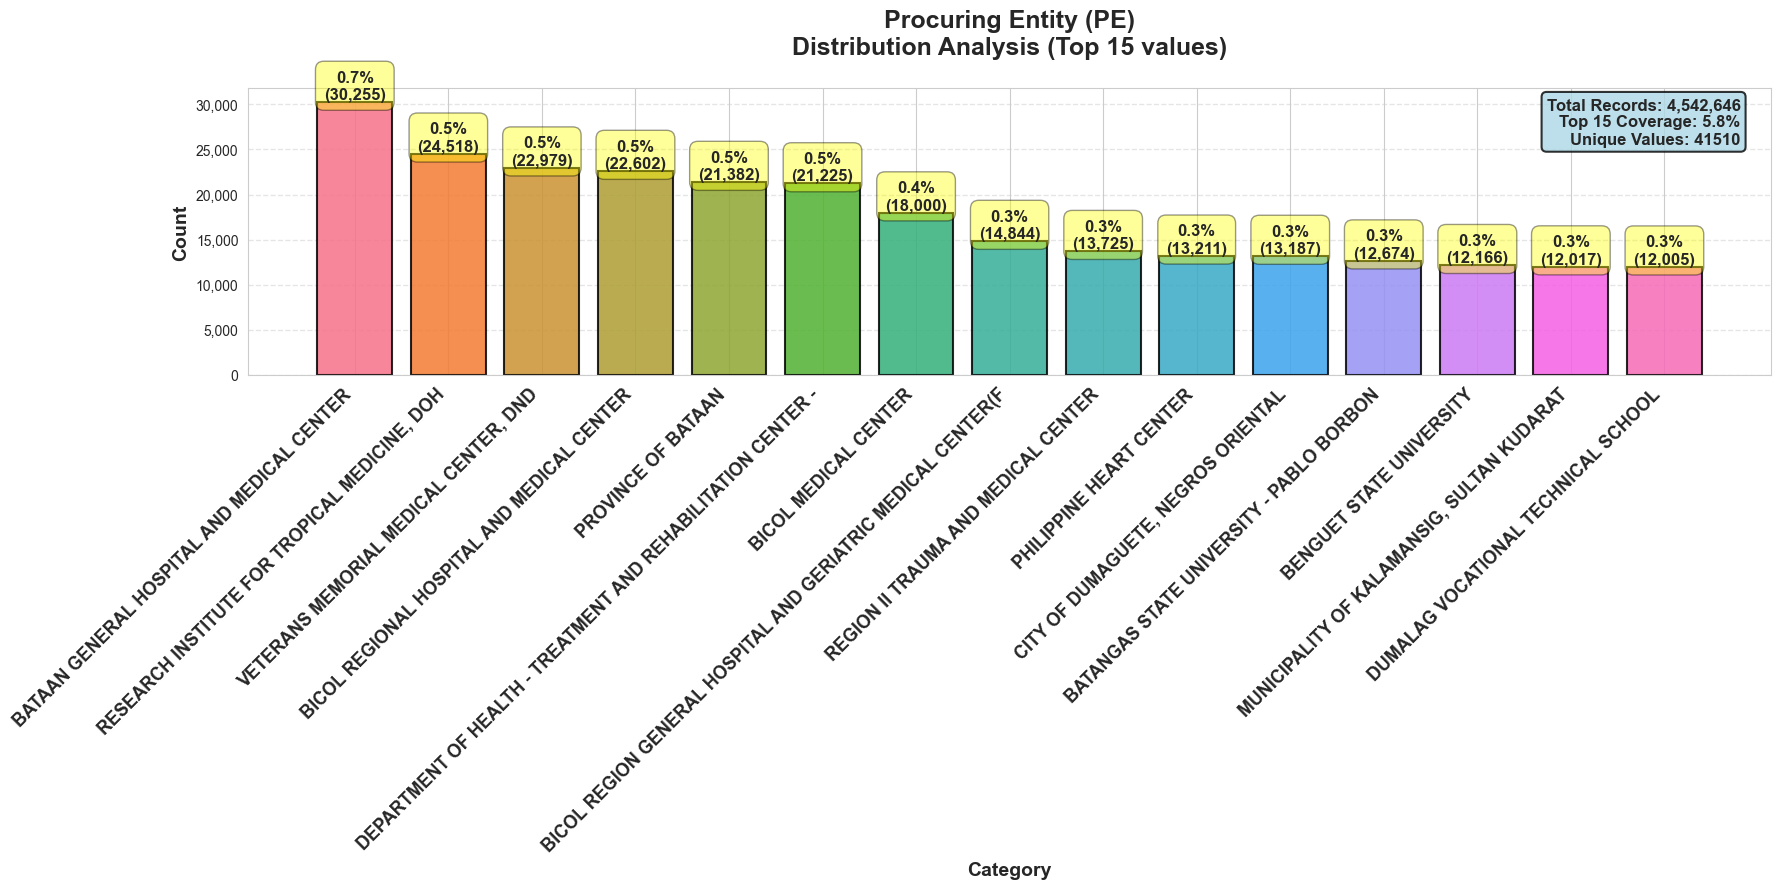


2. Region
--------------------------------------------------------------------------------
Unique values: 34
      Value  Count  Percentage
        NCR 636779       14.02
   Region X 382328        8.42
Region IV-A 375968        8.28
 Region III 335260        7.38
 Region VII 312235        6.87
  Region VI 290951        6.40
   Region V 285926        6.29
Region VIII 255258        5.62
  Region IX 222949        4.91
  Region XI 222383        4.90
   ✓ Graph saved: plot_02_Region.png


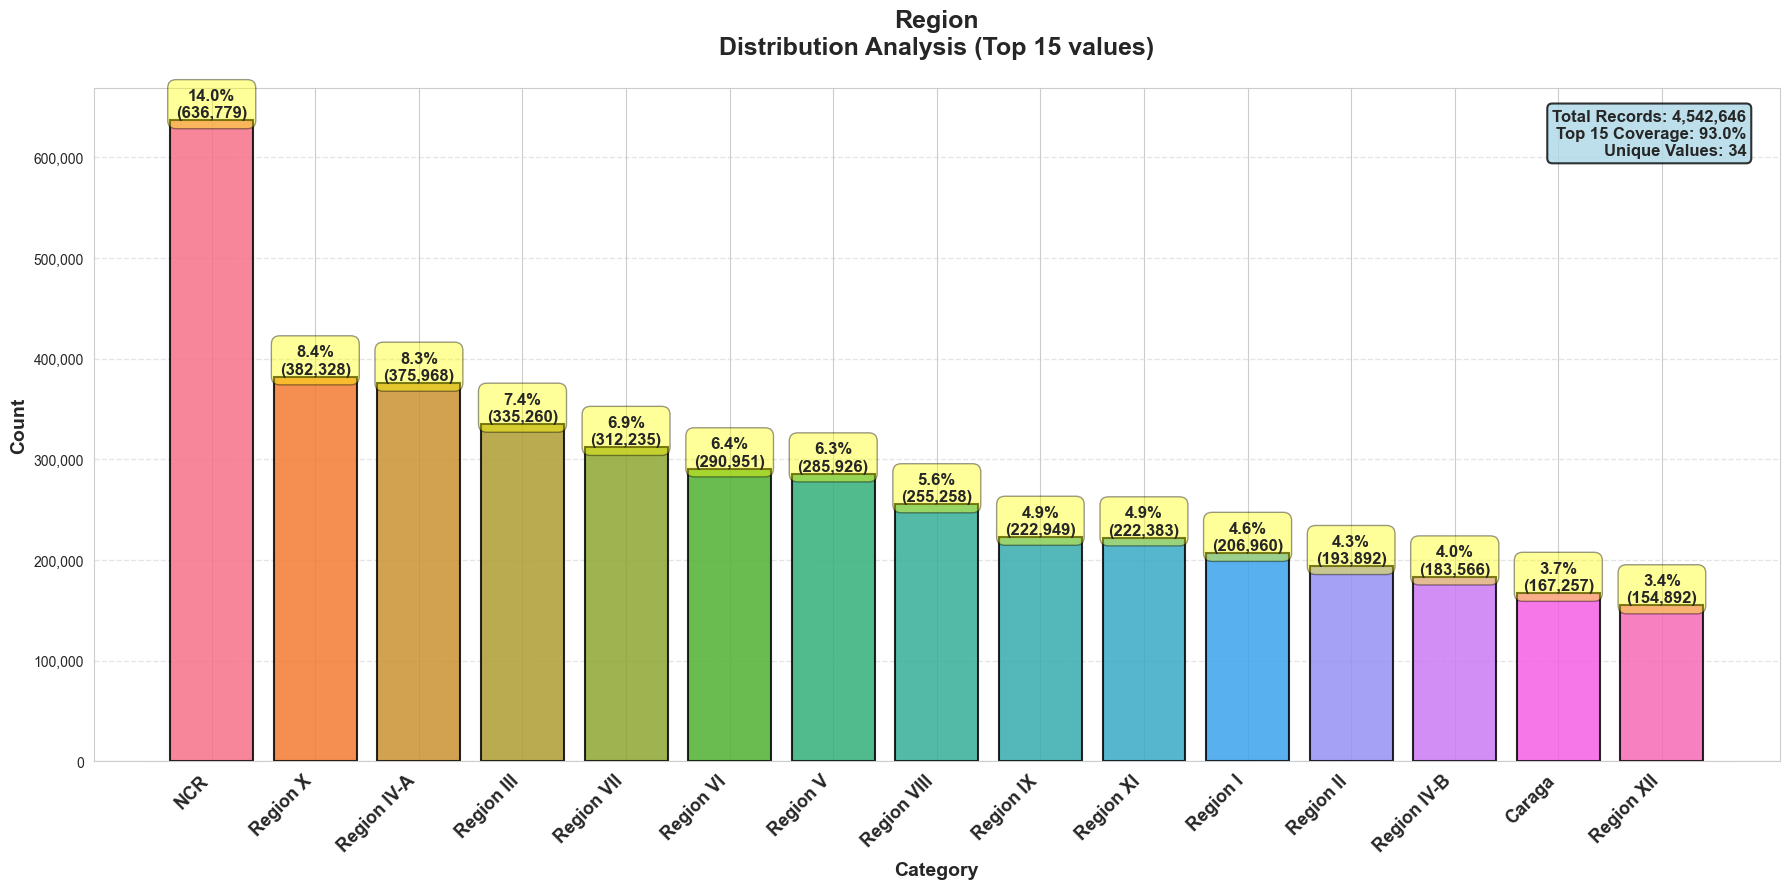


3. Province
--------------------------------------------------------------------------------
Unique values: 130
            Value  Count  Percentage
     Metro Manila 636649       14.01
             Cebu 180979        3.98
         Bukidnon 180527        3.97
Zamboanga Del Sur 141623        3.12
           Iloilo 134356        2.96
 Misamis Oriental 130115        2.86
Negros Occidental 123602        2.72
            Leyte 121610        2.68
    Camarines Sur 118760        2.61
    Davao Del Sur 117326        2.58
   ✓ Graph saved: plot_03_Province.png


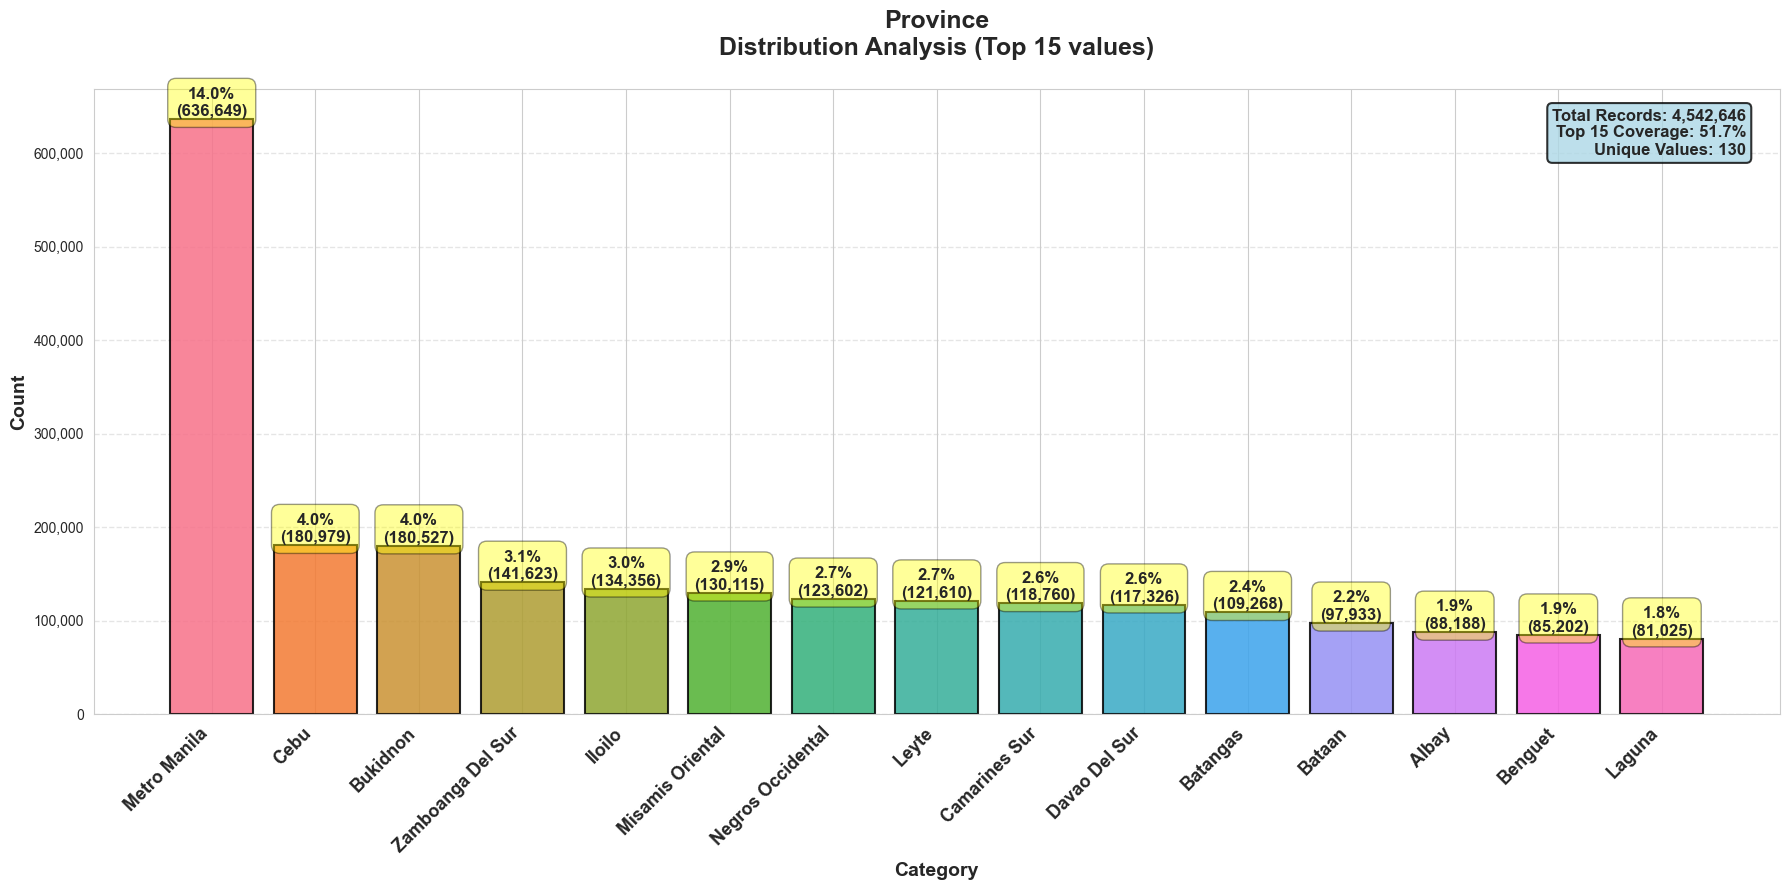


4. City/Municipality
--------------------------------------------------------------------------------
Unique values: 1459
            Value  Count  Percentage
      Quezon City 251880        5.54
           Manila 119408        2.63
       Davao City  79398        1.75
San Fernando City  76936        1.69
        Cebu City  70859        1.56
   Zamboanga City  66710        1.47
      Iloilo City  65217        1.44
     Balanga City  63674        1.40
     Legazpi City  59311        1.31
      Baguio City  57965        1.28
   ✓ Graph saved: plot_04_City_Municipality.png


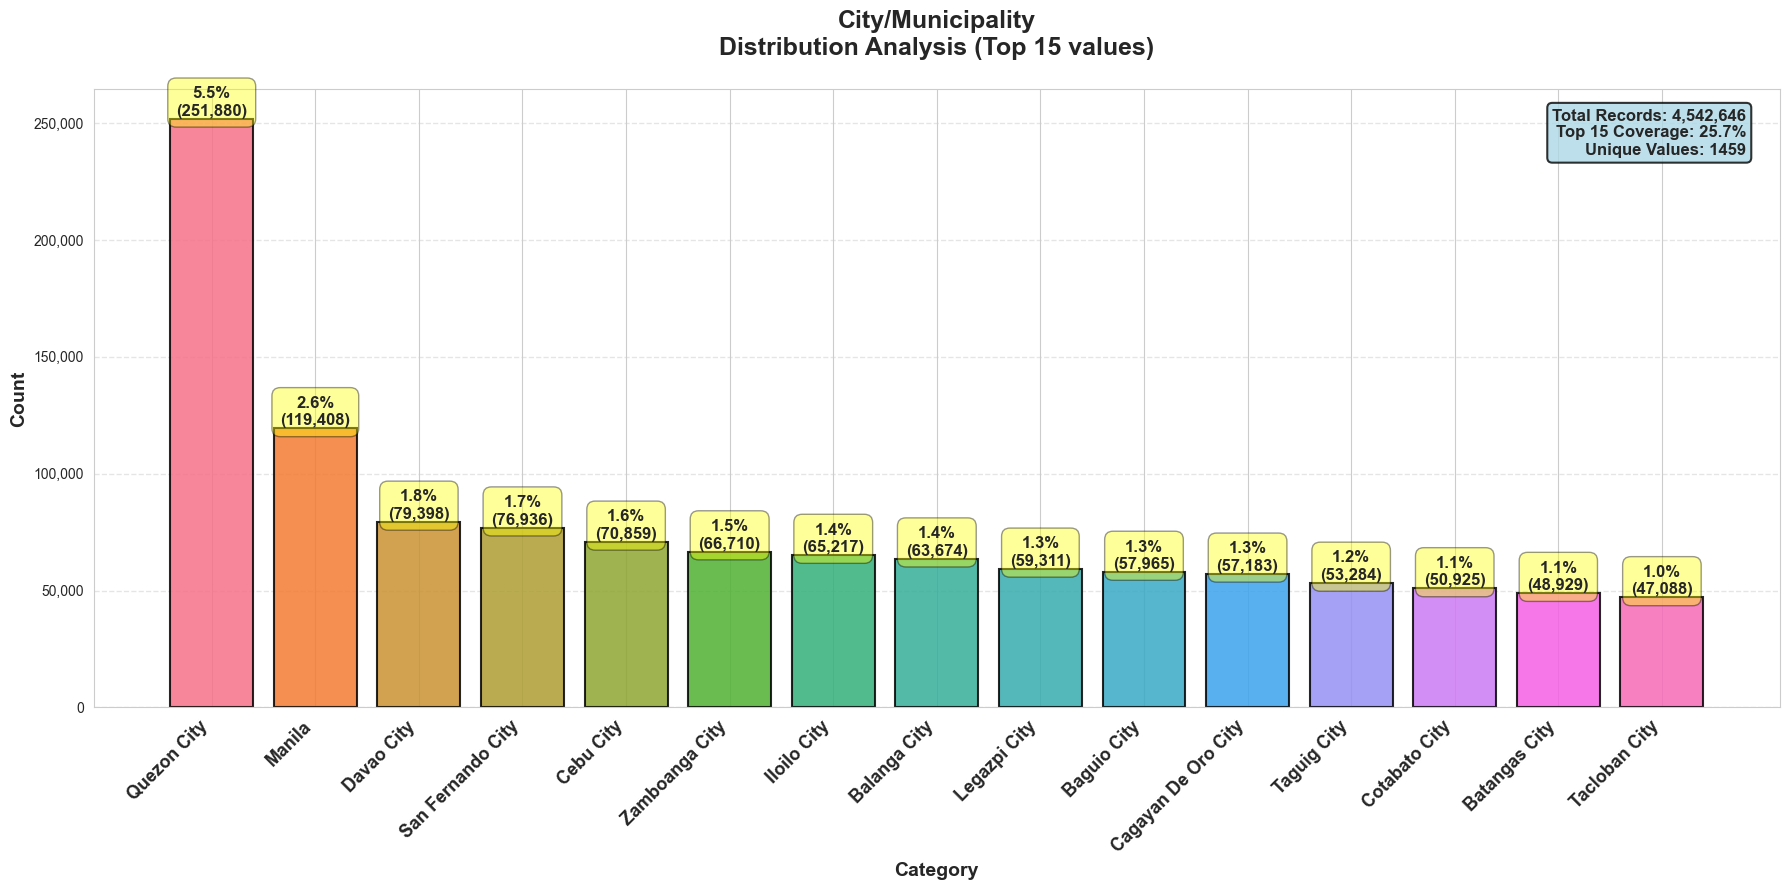


5. Government Branch
--------------------------------------------------------------------------------
Unique values: 7
                      Value   Count  Percentage
                  Executive 4512151       99.33
                Legislative   17435        0.38
                  Judiciary    9486        0.21
      Constitutional Office    2638        0.06
Local Government Unit (LGU)     790        0.02
   Non-benefit Organization      82        0.00
Non-Government Organization      64        0.00
   ✓ Graph saved: plot_05_Government_Branch.png


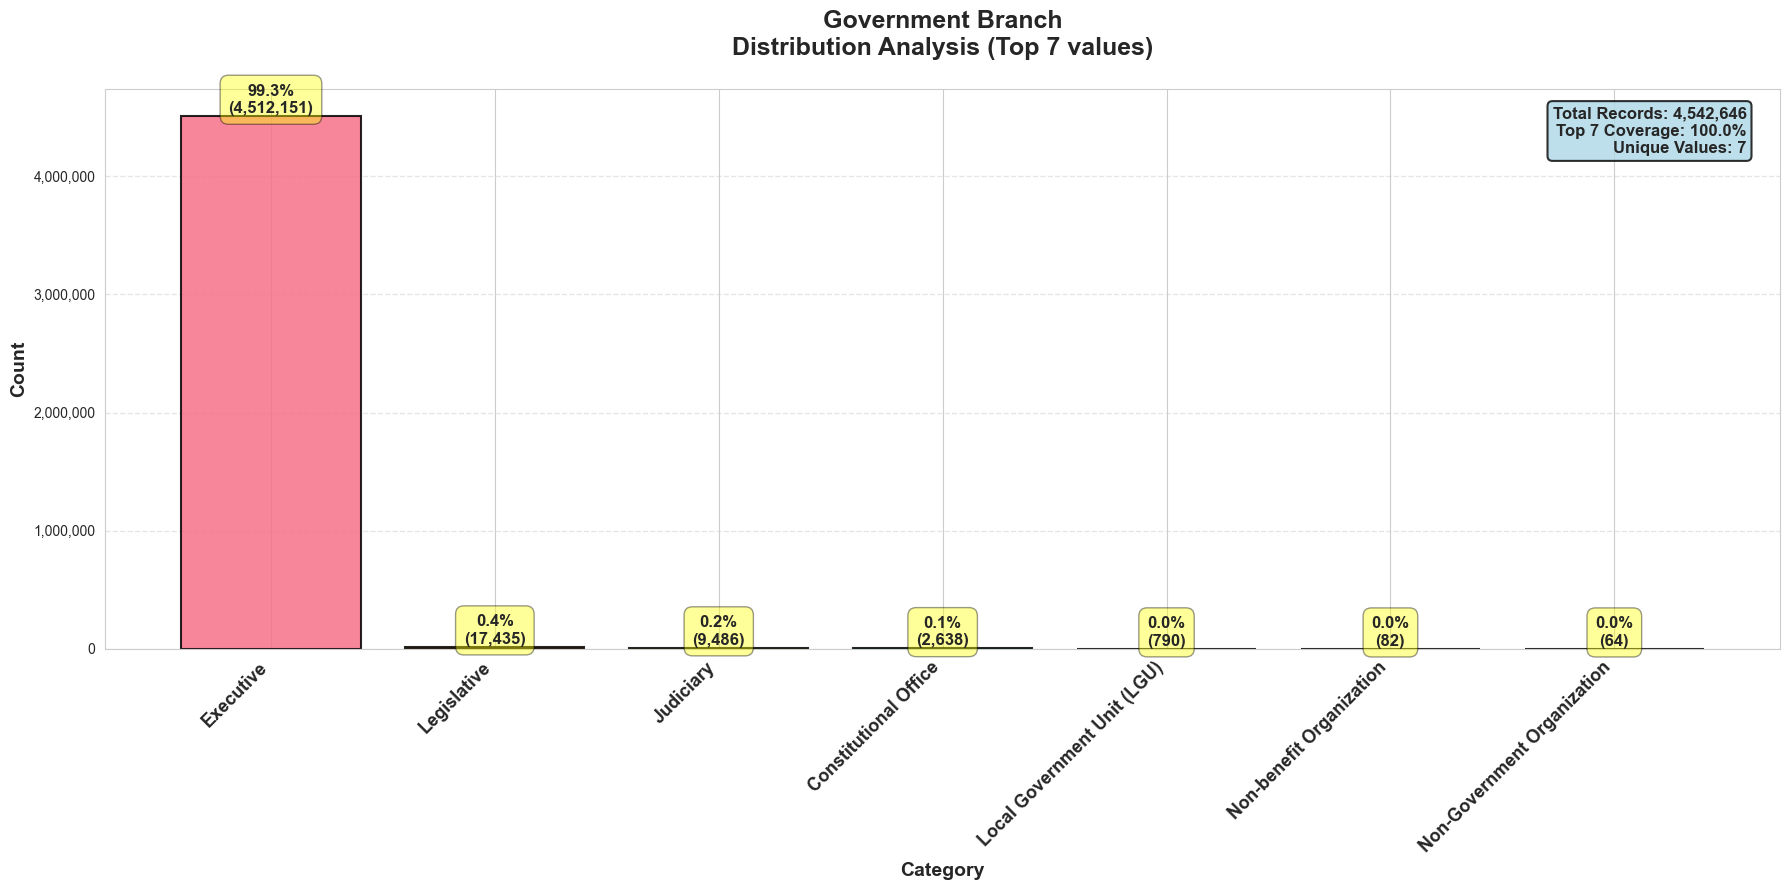


6. PE Organization Type
--------------------------------------------------------------------------------
Unique values: 16
                                         Value  Count  Percentage
                          Municipal Government 929541       20.46
                                    Department 808286       17.79
                                      Hospital 381821        8.41
                                      Barangay 376551        8.29
                               City Government 374983        8.25
Government Owned and/or Controlled Corp.(GOCC) 305955        6.74
                         Provincial Government 290038        6.38
          State Universities or Colleges (SUC) 269974        5.94
                               Attached Agency 245746        5.41
                                    Elementary 225429        4.96
   ✓ Graph saved: plot_06_PE_Organization_Type.png


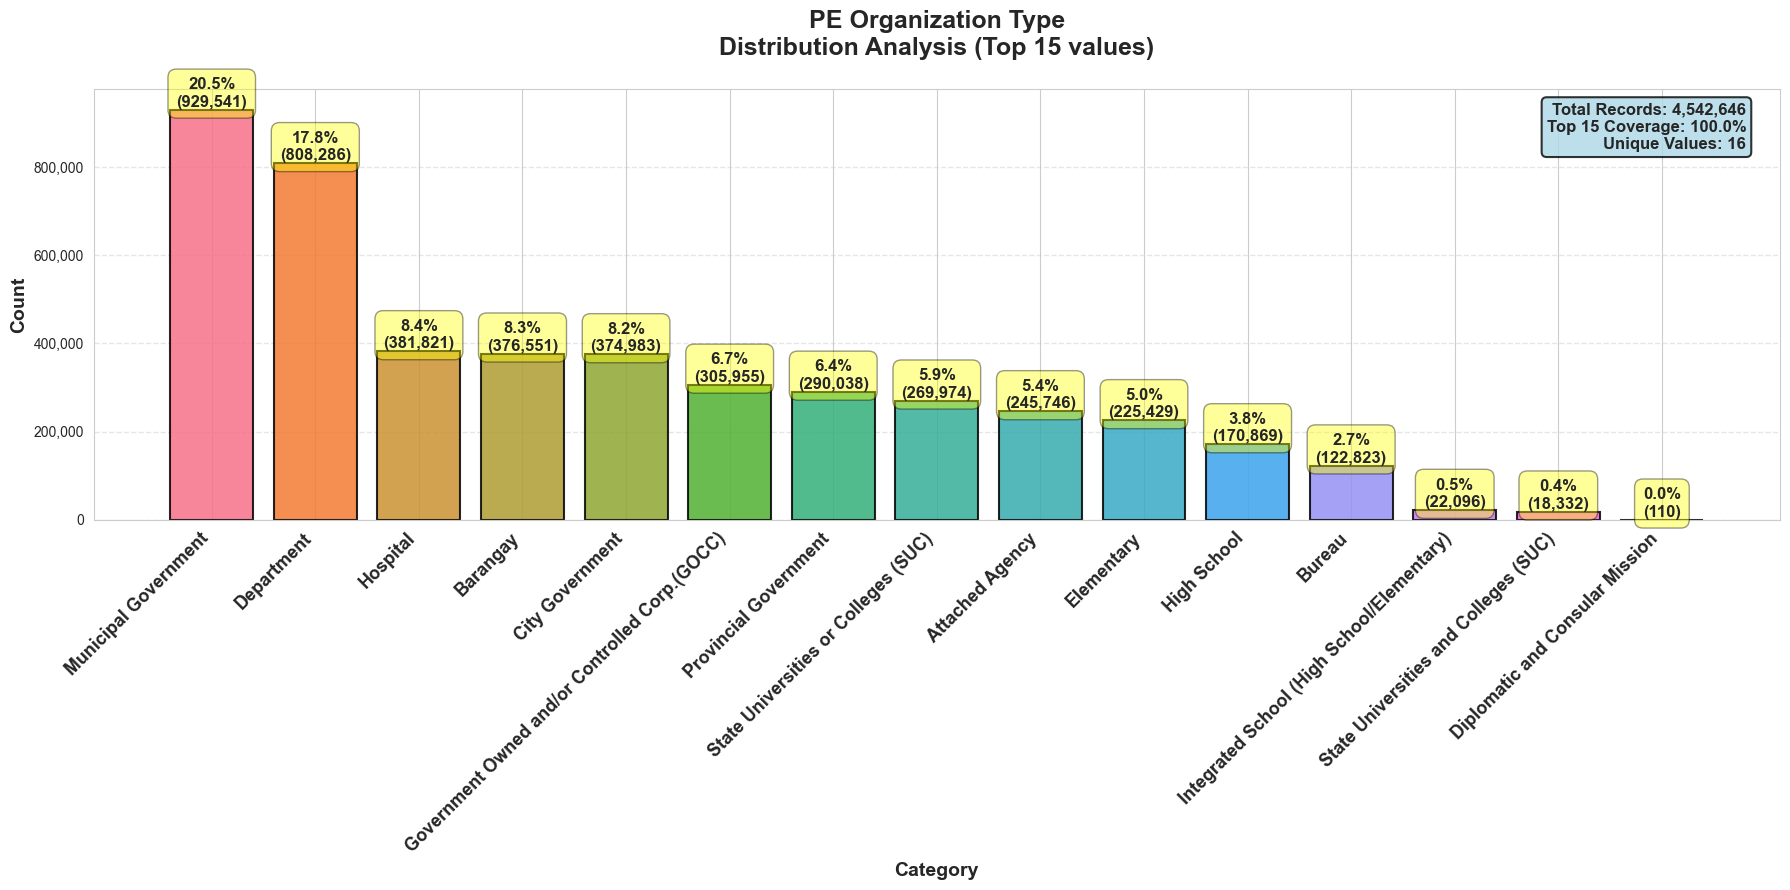


7. PE Organization Type (Grouped)
--------------------------------------------------------------------------------
Unique values: 5
                                              Value   Count  Percentage
                 National Government Agencies (NGA) 1977180       43.52
                       Local Government Units (LGU) 1971113       43.39
Government Owned and Controlled Corporations (GOCC)  305955        6.74
              State Universities and Colleges (SUC)  288306        6.35
                                             Others       8        0.00
   ✓ Graph saved: plot_07_PE_Organization_Type_Grouped.png


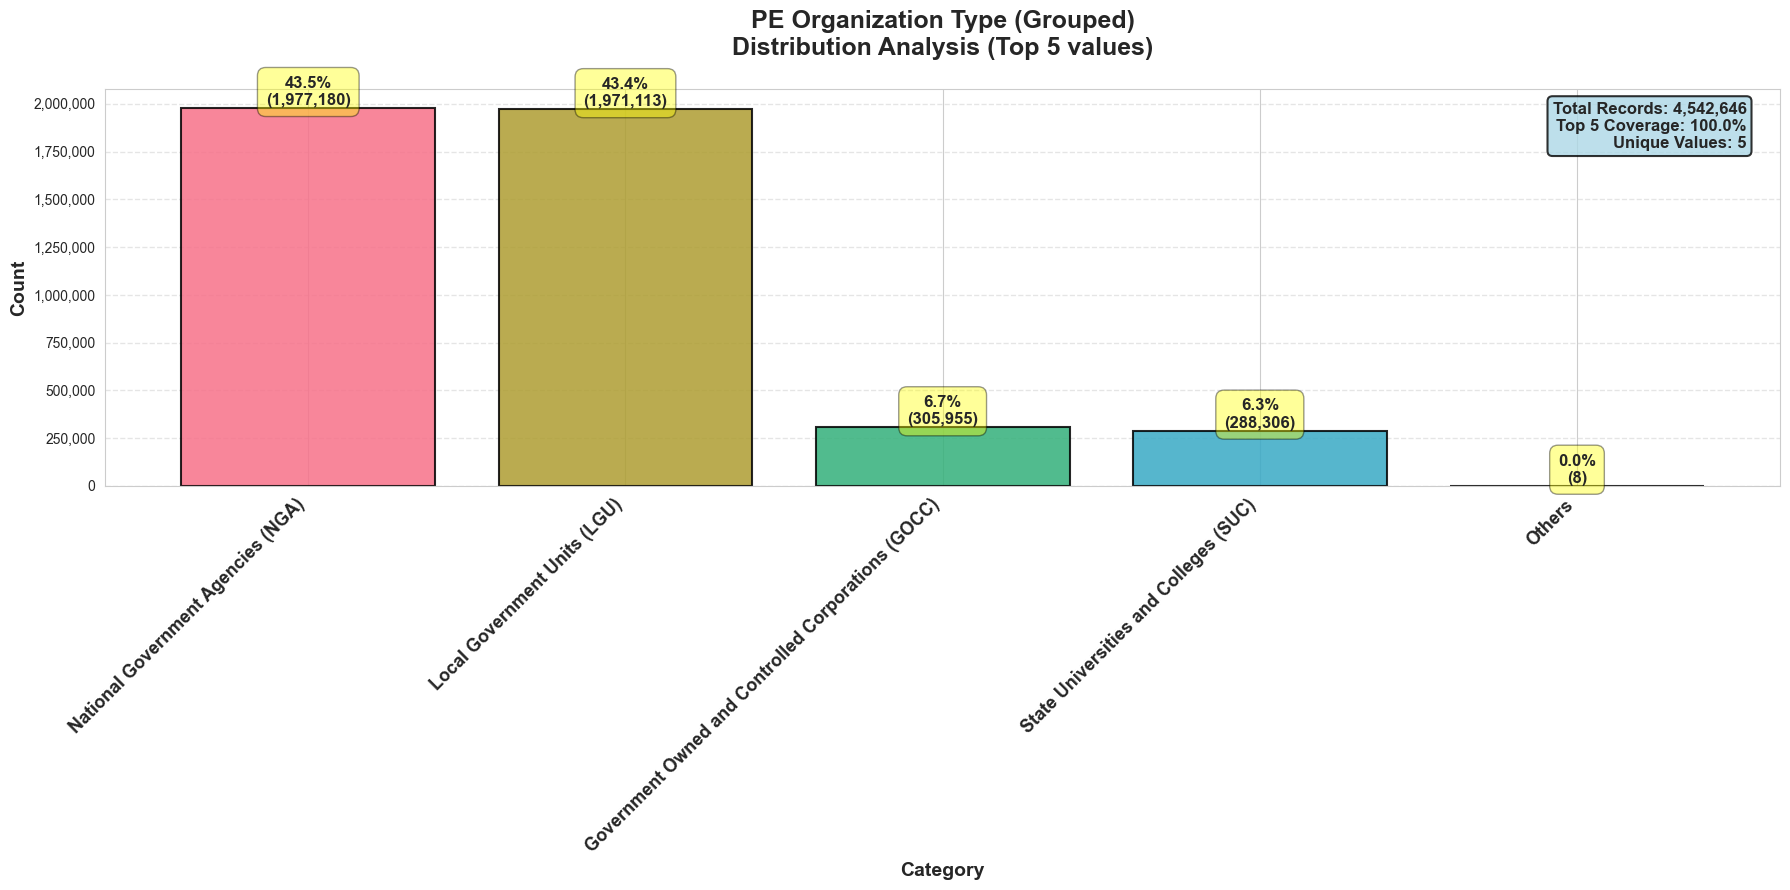


8. Classification
--------------------------------------------------------------------------------
Unique values: 5
                           Value   Count  Percentage
                           Goods 3902020       85.90
                     Civil Works  451895        9.95
Goods - General Support Services  153545        3.38
             Consulting Services   19820        0.44
     Civil Works - Infra Project   15366        0.34
   ✓ Graph saved: plot_08_Classification.png


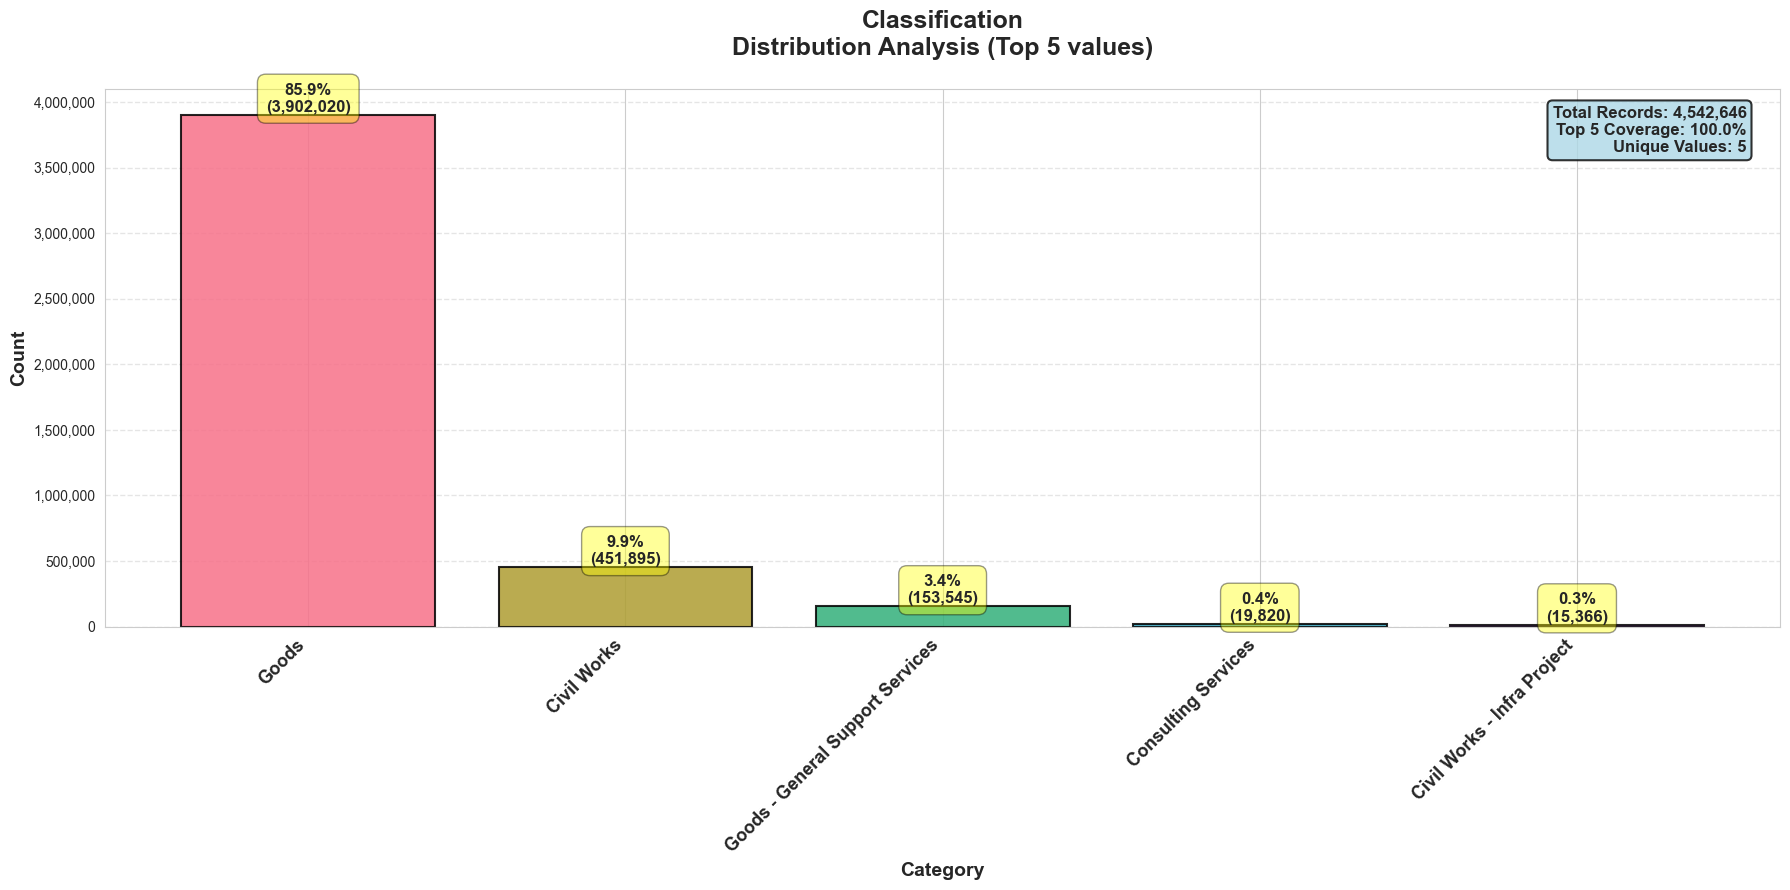


9. Procurement Mode
--------------------------------------------------------------------------------
Unique values: 39
                                                                Value   Count  Percentage
         Negotiated Procurement - Small Value Procurement (Sec. 53.9) 2077062       45.72
                                                       Public Bidding 1468050       32.32
Shopping - Ordinary/Regular Office Supplies & Equipment (Sec. 52.1.b)  649716       14.30
                                              Small Value Procurement   86835        1.91
             Negotiated Procurement - Two Failed Biddings (Sec. 53.1)   71390        1.57
                                 Competitive Bidding (Public Bidding)   54828        1.21
         Negotiated Procurement - Lease of Real Property (Sec. 53.10)   38797        0.85
                                         Direct Contracting (Sec. 50)   23761        0.52
                      Shopping - Unforeseen Contingency (Sec. 52.1.a) 

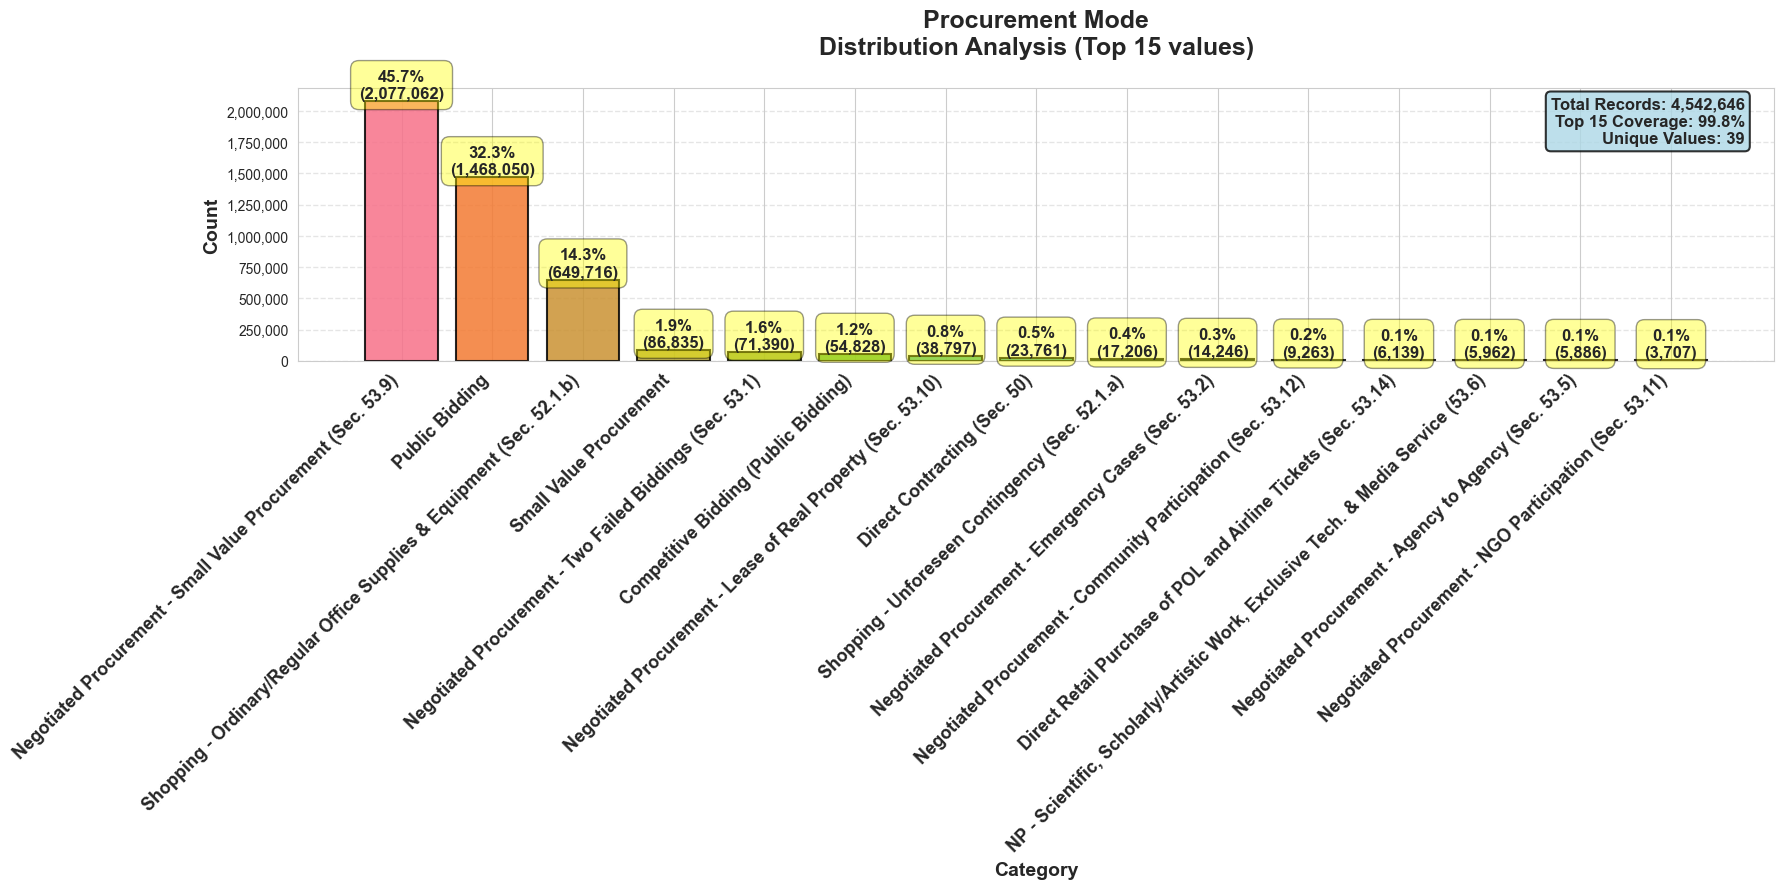


10. Business Category
--------------------------------------------------------------------------------
Unique values: 168
                                     Value  Count  Percentage
                     Construction Projects 432691        9.53
       Construction Materials and Supplies 364696        8.03
               Office Supplies and Devices 272472        6.00
                         Catering Services 262558        5.78
                       General Merchandise 252307        5.55
 Office Equipment Supplies and Consumables 245200        5.40
Medical Supplies and Laboratory Instrument 203047        4.47
                       Drugs and Medicines 160102        3.52
                                Food Stuff 144126        3.17
         Laboratory Supplies and Equipment 112455        2.48
   ✓ Graph saved: plot_10_Business_Category.png


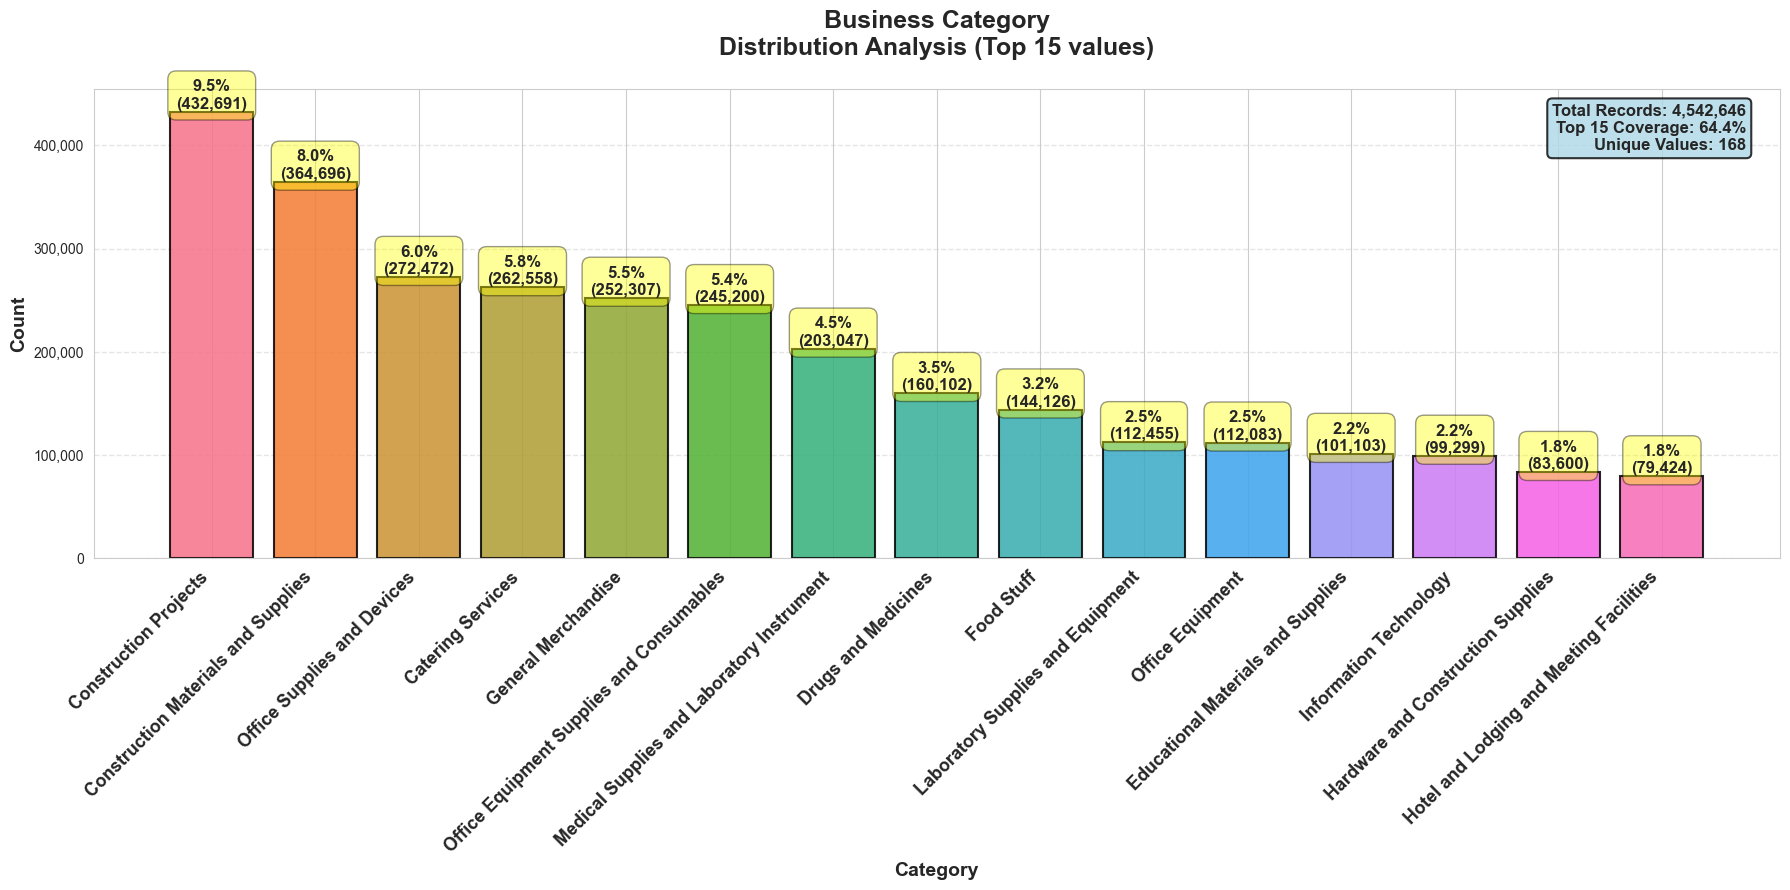


11. Funding Source
--------------------------------------------------------------------------------
Unique values: 5
                                          Value   Count  Percentage
            Government of the Philippines (GOP) 4265983       93.91
                                         Others  107146        2.36
                                World Bank (WB)   15561        0.34
                   Asian Development Bank (ADB)    8174        0.18
Japan Bank for International Cooperation (JBIC)     853        0.02
   ✓ Graph saved: plot_11_Funding_Source.png


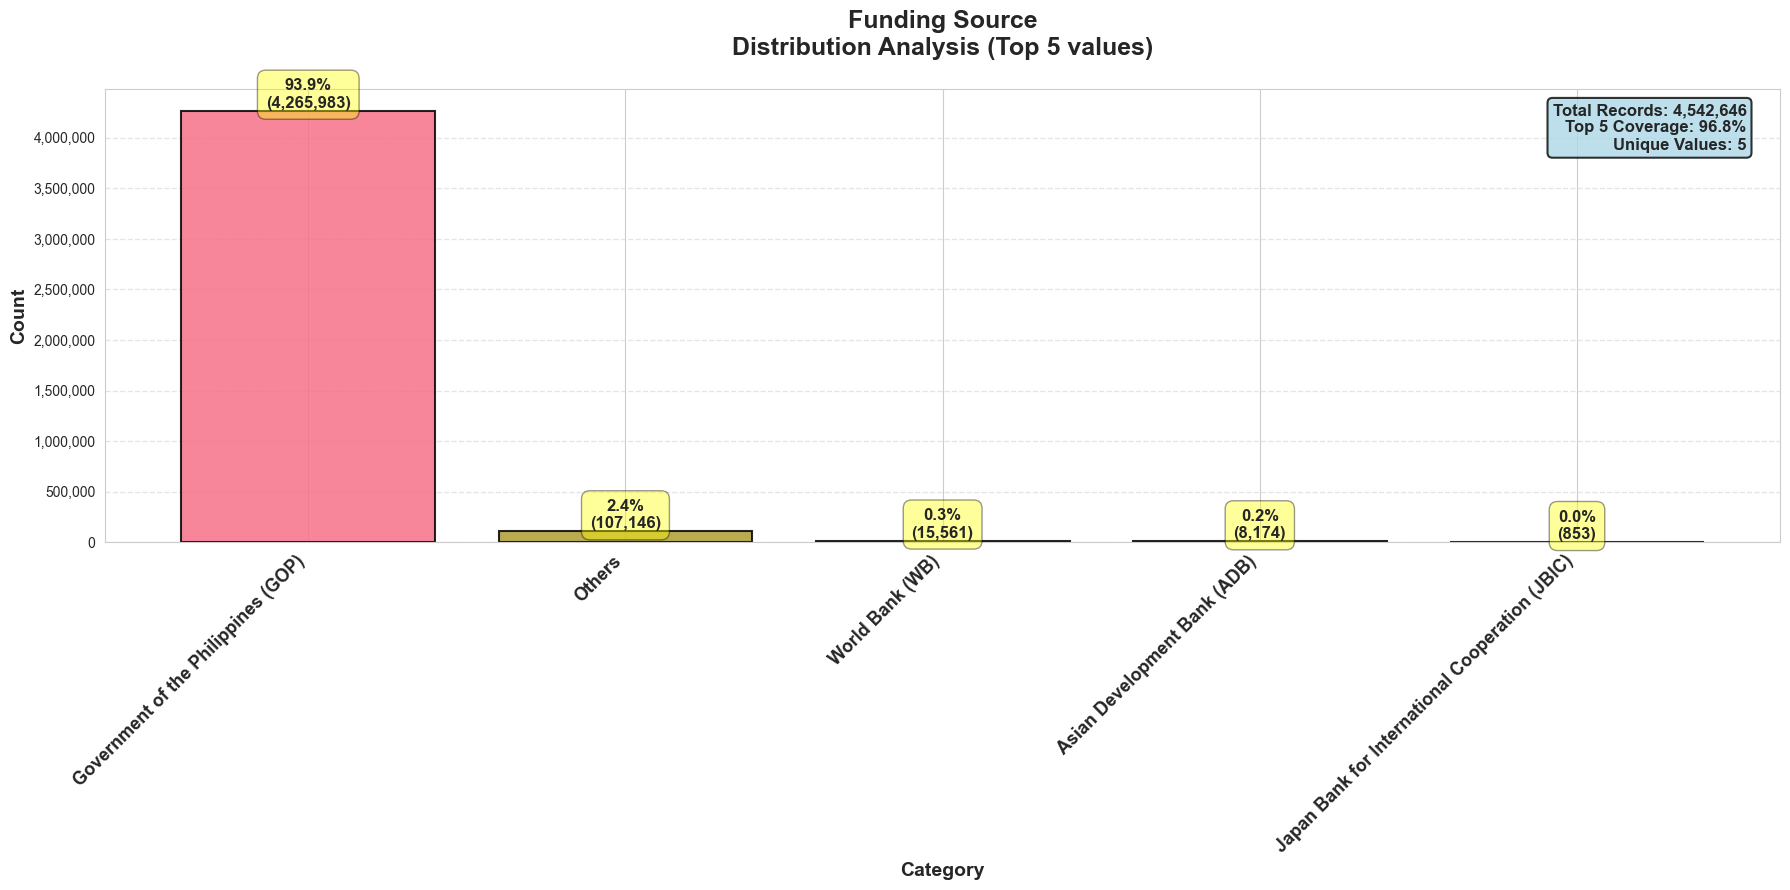


✓ All individual count plots created and saved separately!


In [14]:
print("\n" + "="*80)
print("COUNT ANALYSIS FOR EACH COLUMN")
print("="*80)

# Create separate graphs for each column
for idx, col in enumerate(available_cols):
    value_counts = merged_df_clean[col].value_counts()
    percentages = (value_counts / len(merged_df_clean) * 100).round(2)

    # Print summary
    print(f"\n{idx+1}. {col}")
    print("-" * 80)
    print(f"Unique values: {len(value_counts)}")
    
    summary_data = pd.DataFrame({
        'Value': value_counts.index[:10],
        'Count': value_counts.values[:10],
        'Percentage': percentages.values[:10]
    })
    print(summary_data.to_string(index=False))

    # Create individual figure for each column with larger size
    fig, ax = plt.subplots(figsize=(18, 9))
    
    top_n = min(15, len(value_counts))
    top_values = value_counts.head(top_n)
    top_percentages = percentages.head(top_n)
    
    # Create color gradient for better visibility
    colors = sns.color_palette('husl', len(top_values))
    
    bars = ax.bar(range(len(top_values)), top_values.values, color=colors, alpha=0.85, 
                   edgecolor='black', linewidth=1.5)

    # Add percentage and count labels on bars with better visibility
    for i, (v, p) in enumerate(zip(top_values.values, top_percentages.values)):
        ax.text(i, v, f'{p:.1f}%\n({v:,})', 
               ha='center', va='bottom', fontsize=12, fontweight='bold',
               bbox=dict(boxstyle='round,pad=0.5', facecolor='yellow', alpha=0.4, edgecolor='black'))

    ax.set_xticks(range(len(top_values)))
    ax.set_xticklabels(top_values.index, rotation=45, ha='right', fontsize=13, fontweight='bold')
    ax.set_title(f'{col}\nDistribution Analysis (Top {top_n} values)', 
                fontsize=18, fontweight='bold', pad=25)
    ax.set_ylabel('Count', fontsize=14, fontweight='bold')
    ax.set_xlabel('Category', fontsize=14, fontweight='bold')
    ax.grid(axis='y', alpha=0.5, linestyle='--', linewidth=1)
    ax.set_axisbelow(True)
    
    # Enhance y-axis formatting
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x):,}'))
    
    # Add summary statistics box
    total_in_top = top_values.sum()
    total_percent = (total_in_top / len(merged_df_clean) * 100)
    stats_text = f'Total Records: {len(merged_df_clean):,}\nTop {top_n} Coverage: {total_percent:.1f}%\nUnique Values: {len(value_counts)}'
    ax.text(0.98, 0.97, stats_text,
           transform=ax.transAxes, fontsize=12, verticalalignment='top', horizontalalignment='right',
           bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.8, edgecolor='black', linewidth=1.5),
           fontweight='bold')
    
    plt.tight_layout()
    
    # Save individual plot with descriptive name
    safe_col_name = col.replace("/", "_").replace(" ", "_").replace("(", "").replace(")", "")
    plot_filename = os.path.join(Path(path).parent, f'plot_{idx+1:02d}_{safe_col_name}.png')
    plt.savefig(plot_filename, dpi=150, bbox_inches='tight')
    print(f"   ✓ Graph saved: plot_{idx+1:02d}_{safe_col_name}.png")
    
    plt.show()
    plt.close()

print("\n" + "="*80)
print("✓ All individual count plots created and saved separately!")
print("="*80)

In [22]:
merged_df_clean["Bid Notice Status"].value_counts(normalize=True)

Bid Notice Status
Awarded            0.820793
Failed             0.078685
Cancelled          0.070421
Active             0.020731
Published          0.008685
Shortlisted        0.000451
CONCLUDED          0.000175
CANCEL_APPROVED    0.000060
Name: proportion, dtype: float64

In [21]:
# Removing "Closed" Bid Notice Status
merged_df_clean = merged_df_clean[merged_df_clean["Bid Notice Status"] != "Closed"]

## TASK 5: DATA SCOPING ANALYSIS FOR MODELING

In [8]:
print("="*80)
print("DATA SCOPING ANALYSIS FOR ML MODELING")
print("="*80)

print(f"""
OBJECTIVE: Predict which PhilGEPS public biddings end without a contract
GOAL: Build an ML risk score to help suppliers decide which government tenders to bid on

KEY INSIGHTS FOR DATA SCOPING:

1. **TEMPORAL SCOPE**
   - Dataset spans from 2023 to 2026 (3+ years of historical data)
   - Recommendation: Use 2023-2024 as training data, 2025-2026 for validation/test
   - Consider seasonality and procurement cycles (quarterly patterns visible)
   - Enable time-series validation: earlier data → prediction on later data

2. **GEOGRAPHIC SCOPE**
   - Multiple regions and provinces represented in the data
   - Recommendation: Start with national-level analysis
   - Then drill down to high-volume regions for more granular insights
   - Consider infrastructure and government presence variations by location

3. **ORGANIZATIONAL SCOPE (Procuring Entities)**
   - Different PE organization types have different procurement patterns
   - Recommendation: Stratify analysis by organization type
   - Consider separate models for different PE categories
   - Weight by organizational size/bidding volume

4. **PROCUREMENT MODE & CLASSIFICATION**
   - Different procurement modes (open bidding vs. negotiated procurement)
   - Different classification levels may have different contract completion rates
   - Recommendation: Filter for specific procurement modes most relevant to risk assessment
   - Focus on competitive bidding initially (higher data volume and standardization)

5. **FUNDING SOURCE**
   - Budget source might correlate with contract completion and project viability
   - Recommendation: Include as a feature; check for data quality/completeness
   - May need categorization or grouping for sparse categories

6. **DATA QUALITY ASSESSMENT**
   - Duplicates removed: {:.2f}% of original data
   - Missing values: Carefully handle by column importance
   - Long-tail distributions: Some columns have sparse representations
   - Recommendation: Use one-hot encoding or grouping for sparse categories

7. **SUGGESTED DATA SLICING STRATEGIES**

   OPTION A (Conservative - High Quality Focus):
   - Focus on major procurement modes (likely higher data quality)
   - Exclude small PE organizations with < 10 biddings
   - Use most recent 2 years of complete data (2024-2025)
   - Better for initial model development and validation

   OPTION B (Comprehensive - Maximum Learning):
   - Include all procurement modes (capture diverse risk scenarios)
   - Weight samples by time and procurement volume
   - Use 3+ years of historical data (2023-2026) with time-based validation
   - Better for understanding full spectrum of bidding behaviors

8. **TARGET VARIABLE ENGINEERING**
   - CRITICAL: Need to identify what "ended without contract" means in this dataset
   - Check for: completion status field, contract award indicators, bidding outcome
   - May need to infer from date ranges, project lifecycle indicators, or absence of records
   - Decision: Define success = contract awarded, failure = no contract or withdrawn

9. **FEATURE ENGINEERING OPPORTUNITIES**
   - Time-based: Bid duration, time of year, historical trends
   - Organization-based: PE bidding frequency, historical success rate, org type
   - Geographic: Region/province demand characteristics
   - Market-based: Seasonal/cyclical patterns, business category trends
   - Amount-based: Budget ranges, funding distribution, contract value ranges

10. **CLASS BALANCE CONSIDERATION**
   - Likely imbalanced target: most bids lead to contracts
   - Recommendation: Use stratified sampling, SMOTE, or class weights in model
   - Metric focus: Precision/Recall/F1 > Accuracy

11. **MODEL ARCHITECTURE RECOMMENDATIONS**
   - Start with: Logistic Regression, Random Forest, XGBoost
   - Advanced: Temporal models considering procurement cycles
   - Ensemble: Combine multiple models trained on different data slices
   - Risk stratification: Create 3-5 risk tiers instead of binary classification

12. **VALIDATION STRATEGY**
   - Time-based split: Train on 2023-2024, validate on 2025, test on 2026
   - Geographic hold-out: Train on major regions, test on underrepresented areas
   - Organization hold-out: Test on PE types not well-represented in training
   - Regular re-training needed as new procurement cycles emerge
""".format((before_drop - after_drop)/before_drop*100))

print("\n" + "="*80)

SyntaxError: f-string: valid expression required before ':' (745977507.py, line 41)

In [ ]:
# Save cleaned dataset for future analysis
output_path = os.path.join(Path(path).parent, 'merged_cleaned_data.csv')
merged_df_clean.to_csv(output_path, index=False)

print("\n" + "="*80)
print("ANALYSIS COMPLETE")
print("="*80)
print(f"\n✓ Cleaned merged dataset saved to:")
print(f"  {output_path}")
print(f"  Shape: {merged_df_clean.shape[0]:,} rows × {merged_df_clean.shape[1]} columns")
print(f"\n✓ Count plots visualization saved as: count_plots_analysis.png")
print(f"\n✓ All tasks completed successfully!")


## Evaluating bidding status

In [ ]:
merged_df_clean[""]

In [17]:
merged_df_clean.head()

,Procuring Entity (PE),Region,Province,City/Municipality,Government Branch,PE Organization Type,PE Organization Type (Grouped),Bid Reference No.,Notice Title,Classification,...,Delivery Period/Contract Duration,Lot Type,Item Code,Item/Lot Name,Item/Lot Description,Unit of Measure,Item/Lot Name.1,Published Date (Award),Award Notice Status (Item),Awardee Size (MSME Category)
1282033,DOJ-NATIONAL PROSECUTION SERVICE XI,Region XI,Davao Del Sur,Davao City,Executive,Department,National Government Agencies (NGA),0,Venue with Meals for the 2025 TEPLEA on 12 Sep...,Goods - General Support Services,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1282034,"CITY OF KORONADAL, SOUTH COTABATO",Region XII,South Cotabato,Koronadal City,Executive,City Government,Local Government Units (LGU),0,LEASE OF VENUE & ACCOMMODATION W/ MEALS & SNAC...,Goods,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1282035,SOCIAL SECURITY SYSTEM - LUZON CENTRAL 2,Region III,Pampanga,San Fernando City,Executive,Government Owned and/or Controlled Corp.(GOCC),Government Owned and Controlled Corporations (...,0,PROCUREMENT OF MEALS (AM SNACK AND LUNCH) AND ...,Civil Works,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1282036,"MUNICIPALITY OF PAGSANJAN, LAGUNA",Region IV-A,Laguna,Pagsanjan,Executive,Municipal Government,Local Government Units (LGU),0,AUDIO-VISUAL SYSTEM FOR THE INAUGURATION OF EL...,Goods,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1282037,"MUNICIPALITY OF MABINI, PANGASINAN",Region I,Pangasinan,Mabini,Executive,Municipal Government,Local Government Units (LGU),0,Purchase of Diesel Fuel for the Office of the ...,Goods,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [19]:
# Does Bid Reference number unique per entry 
merged_df_clean["Bid Reference No."].is_unique

False

In [20]:
# Give me few entries that have the same Bid Reference No.
merged_df_clean[merged_df_clean.duplicated(subset=["Bid Reference No."], keep=False)]

,Procuring Entity (PE),Region,Province,City/Municipality,Government Branch,PE Organization Type,PE Organization Type (Grouped),Bid Reference No.,Notice Title,Classification,...,Delivery Period/Contract Duration,Lot Type,Item Code,Item/Lot Name,Item/Lot Description,Unit of Measure,Item/Lot Name.1,Published Date (Award),Award Notice Status (Item),Awardee Size (MSME Category)
1282033,DOJ-NATIONAL PROSECUTION SERVICE XI,Region XI,Davao Del Sur,Davao City,Executive,Department,National Government Agencies (NGA),0,Venue with Meals for the 2025 TEPLEA on 12 Sep...,Goods - General Support Services,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1282034,"CITY OF KORONADAL, SOUTH COTABATO",Region XII,South Cotabato,Koronadal City,Executive,City Government,Local Government Units (LGU),0,LEASE OF VENUE & ACCOMMODATION W/ MEALS & SNAC...,Goods,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1282035,SOCIAL SECURITY SYSTEM - LUZON CENTRAL 2,Region III,Pampanga,San Fernando City,Executive,Government Owned and/or Controlled Corp.(GOCC),Government Owned and Controlled Corporations (...,0,PROCUREMENT OF MEALS (AM SNACK AND LUNCH) AND ...,Civil Works,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1282036,"MUNICIPALITY OF PAGSANJAN, LAGUNA",Region IV-A,Laguna,Pagsanjan,Executive,Municipal Government,Local Government Units (LGU),0,AUDIO-VISUAL SYSTEM FOR THE INAUGURATION OF EL...,Goods,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1282037,"MUNICIPALITY OF MABINI, PANGASINAN",Region I,Pangasinan,Mabini,Executive,Municipal Government,Local Government Units (LGU),0,Purchase of Diesel Fuel for the Office of the ...,Goods,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6634856,DPWH - ILIGAN CITY DISTRICT ENGINEERING OFFICE,Region X,Lanao Del Norte,Iligan City,Executive,NaN,NaN,81184,Procurement of Personal Protective Equipment f...,Goods,...,30 days,Single Lot,46181605.0,Safety shoes,Safety shoes,Pair,NaN,NaN,NaN,NaN
6634870,DEPARTMENT OF EDUCATION - DIVISION OF CAGAYAN,Region II,Cagayan,Tuguegarao City,Executive,Department,National Government Agencies (NGA),81202,SUPPLY AND DELIVERY OF MULTIVITAMINS WITH MINE...,Goods,...,30 days,Single Lot,11101713.0,Iron,Iron,Lot,NaN,NaN,NaN,NaN
6634871,DEPARTMENT OF EDUCATION - DIVISION OF CAGAYAN,Region II,Cagayan,Tuguegarao City,Executive,Department,National Government Agencies (NGA),81202,SUPPLY AND DELIVERY OF MULTIVITAMINS WITH MINE...,Goods,...,30 days,Single Lot,11101719.0,Zinc,Zinc,Lot,NaN,NaN,NaN,NaN
6634875,DEPARTMENT OF EDUCATION - ISABELA,Region II,Isabela,Ilagan City,Executive,Department,National Government Agencies (NGA),81206,"PRINTING, SUPPLY, AND DELIVERY OF ARAL MATERIALS",Goods,...,1 months,Single Lot,82121503.0,Digital printing,Digital printing,Sheet,NaN,NaN,NaN,NaN


In [1]:
merged_df[merged_df["Bid Reference No."] == 1282033]

NameError: name 'merged_df' is not defined